#1. Introduction

The aim of this assignment is to identify communities in Zachary's Karate Club graph using recursive spectral partitioning based on modularity. The graph contains 34 nodes representing club members and edges representing friendships.

The analysis proceeds by constructing the modularity matrix, using its leading eigenvector to propose community splits, and recursively applying the procedure until no further acceptable split is found. The resulting community structure is visualized after each split. Finally, degree centrality, betweenness centrality, closeness centrality, and the clustering coefficient are examined across the iterations.

The notebook is organized so that the code, its output, and the explanation of each stage appear together.

#2. Import libraries and load the graph

We use NetworkX to construct and analyze the network, NumPy for matrix and eigenvalue calculations, and Matplotlib for visualizations.

The built-in karate_club_graph() function provides Zachary's Karate Club network. We first inspect the number of nodes and edges.

The initial graph is drawn before partitioning. A fixed spring layout is used so that node positions can be reused in the visualizations after each split. This makes the changes in community membership easier to compare.

Number of nodes: 34
Number of edges: 78


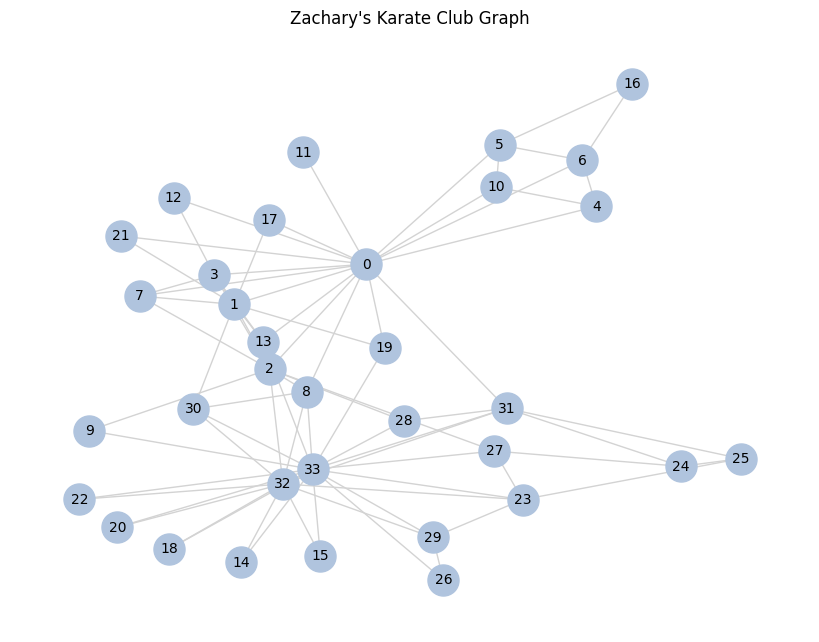

In [79]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

G = nx.karate_club_graph()

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

# Fixed layout, reused for every figure in this notebook
pos = nx.spring_layout(G, seed=42, weight=None)

plt.figure(figsize=(8, 6))
nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=500,
    font_size=10,
    node_color="lightsteelblue",
    edge_color="lightgray"
)
plt.title("Zachary's Karate Club Graph")
plt.show()

#3. Construct modularity matrix  
The adjacency matrix \(A\) represents the edges in the graph: \(A_{ij}=1\) when nodes \(i\) and \(j\) are connected, and \(0\) otherwise. The degree vector \(k\) contains the degree of each node, and \(m\) is the total number of edges.

The global modularity matrix is

$$
B = A - \frac{kk^T}{2m}
$$


In [80]:
A = nx.to_numpy_array(G, nodelist=sorted(G.nodes()),weight=None)
nodes=sorted(G.nodes())
k = np.array([G.degree(i) for i in nodes])

m = G.number_of_edges()

print("Adjacency matrix shape:", A.shape)
print("Degree vector shape:", k.shape)
print("Number of edges:", m)
B = A - np.outer(k, k) / (2 * m)

print("Modularity matrix shape:", B.shape)
print("Is B symmetric?", np.allclose(B, B.T))
print("Sum of all entries:", B.sum())

Adjacency matrix shape: (34, 34)
Degree vector shape: (34,)
Number of edges: 78
Modularity matrix shape: (34, 34)
Is B symmetric? True
Sum of all entries: -3.774758283725532e-15


#4. Initial spectral analysis

We calculate the eigenvalues and eigenvectors of the global modularity matrix. The eigenvector corresponding to the largest eigenvalue is the leading eigenvector. Its entries provide the sign-based assignment used to propose a division of a network.

The recursive procedure below applies the corresponding analysis to each community, using the appropriate restricted modularity matrix and its diagonal correction.

In [81]:
eigenvalues, eigenvectors = np.linalg.eigh(B)

index = np.argmax(eigenvalues)

leading_eigenvalue = eigenvalues[index]
leading_eigenvector = eigenvectors[:, index]

print("Leading eigenvalue:", leading_eigenvalue)
print("Leading eigenvector:")
print(leading_eigenvector)

# Sign-based two-way split from the global leading eigenvector
s = np.where(leading_eigenvector > 0, 1, -1)
print("\nGroup sizes of the global two-way split:", (s > 0).sum(), "and", (s < 0).sum())
print("Q of this split = %.4f" % (s @ B @ s / (4 * m)))

Leading eigenvalue: 4.977080225729887
Leading eigenvector:
[ 0.38754293  0.26955742  0.13189899  0.25345236  0.13400323  0.14573804
  0.14573804  0.20935954 -0.05447571 -0.04785238  0.13400323  0.07784279
  0.12874396  0.13502861 -0.13943288 -0.13943288  0.05851821  0.13197981
 -0.13943288  0.05764888 -0.13943288  0.13197981 -0.13943288 -0.21674712
 -0.0563305  -0.07540039 -0.11580257 -0.10276487 -0.06834027 -0.20629456
 -0.09626391 -0.10185678 -0.32390453 -0.36983786]

Group sizes of the global two-way split: 16 and 18
Q of this split = 0.3715


#5.Steps before recursive partitioning

A mapping from node labels to matrix indices and a few helper functions are prepared. Two data structures are initialized:
- `split_history` stores the partition and its modularity $Q$ at each iteration.
- `centrality_history` stores the four node metrics at each iteration.

Iteration 0 represents the original, unsplit graph: its partition is a single community, $Q=0$, and its centrality values are computed on the full graph. The helper `modularity(partition)` computes $Q=\frac{1}{2m}\sum_{i,j\ \text{in same group}}B_{ij}$ for any number of groups.

In [82]:
# Map each node label to its position in the modularity matrix
node_to_index = {node: i for i, node in enumerate(nodes)}

def modularity(partition):
    # Q of a partition
    total = 0.0
    for group in partition:
        idx = [node_to_index[v] for v in group]
        total += B[np.ix_(idx, idx)].sum()
    return total / (2 * m)

def node_metrics(H):
    # The four required NetworkX metrics
    return {
        "degree": nx.degree_centrality(H),
        "betweenness": nx.betweenness_centrality(H),
        "closeness": nx.closeness_centrality(H),
        "clustering": nx.clustering(H)
    }

def metrics_for_partition(partition):
    # Metrics of every node inside the subgraph induced by its own community
    out = {"degree": {}, "betweenness": {}, "closeness": {}, "clustering": {}}
    for group in partition:
        res = node_metrics(G.subgraph(group))
        for name in out:
            for node in group:
                out[name][node] = res[name][node]
    return out

# Store the results at each iteration
split_history = [{"level": 0, "groups": [nodes.copy()], "Q": 0.0}]
centrality_history = {0: metrics_for_partition([nodes.copy()])}   # whole-graph metrics

community_colors = {}
next_color_id = 0

print("Nodes mapped:", len(node_to_index))
print("Iteration 0 metrics computed for", len(centrality_history[0]["degree"]), "nodes")

Nodes mapped: 34
Iteration 0 metrics computed for 34 nodes


#6. Recursive spectral community detection

To split a community $C$, we take the block of $B$ for its nodes and use the sign of its leading eigenvector, exactly as in the two-way case. We then repeat on each new group until no split helps.

One change from the handout: For a sub-community, the plain block of $B$ is not enough. Following Newman (2006, Eq. 6), we subtract each row sum from the diagonal:
$$B^{(C)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in C}B_{il},\qquad \Delta Q=\frac{1}{4m}\,s^\top B^{(C)}s.$$
For the whole graph the row sums are zero, so nothing changes at the first split. With the plain block the top eigenvalue would stay positive (about 9.85 for the 16-node group) and the algorithm would never stop.

**A split is accepted only if** $\lambda_1>0$, the sign-rounded split has $\Delta Q>0$, and both groups are non-empty.


In [83]:
colours = ["#9ECAE1", "#F4A6A6", "#B5E3A8", "#FFD58A", "#CDB4F0", "#8FDCCB", "#F7B7D9", "#D6D6A0"]

def recursive_split(G, B, nodes, communities, level=0, partition=None):
    global next_color_id

    if partition is None:
        partition = [nodes.copy()]

    # Extract the community block from the original modularity matrix
    indices = [node_to_index[node] for node in nodes]
    B_sub = B[np.ix_(indices, indices)]
    B_sub = B_sub - np.diag(B_sub.sum(axis=1)) # Newman's generalised matrix B^(C)

    # Find the leading eigenpair
    eigenvalues, eigenvectors = np.linalg.eigh(B_sub)
    index = np.argmax(eigenvalues)
    leading_eigenvalue = eigenvalues[index]
    leading_eigenvector = eigenvectors[:, index]

    print(f"\nLevel {level}: Community = {nodes}")
    print(f"Leading eigenvalue = {leading_eigenvalue:.4f}")

    # Stop if the leading eigenvalue is not positive
    if leading_eigenvalue <= 1e-8:
        communities.append(nodes.copy())
        return

    # Divide nodes according to the eigenvector signs
    s = np.where(leading_eigenvector > 0, 1, -1)

    # Check whether the split increases modularity
    delta_Q = (s @ B_sub @ s) / (4 * G.number_of_edges())
    print(f"Delta Q = {delta_Q:.4f}")

    if delta_Q <= 1e-8:
        communities.append(nodes.copy())
        return

    group_1 = [nodes[i] for i in range(len(nodes)) if s[i] > 0]
    group_2 = [nodes[i] for i in range(len(nodes)) if s[i] < 0]

    # Stop if either group is empty
    if not group_1 or not group_2:
        communities.append(nodes.copy())
        return

    # Update the partition after splitting
    partition.remove(nodes)
    partition.extend([group_1.copy(), group_2.copy()])

    # Record the current partition and its modularity
    iteration = len(split_history)
    Q = modularity(partition)
    split_history.append({
        "level": iteration,
        "groups": [group.copy() for group in partition],
        "Q": Q
    })

    # Store centrality metrics (inside each current community) after each split
    centrality_history[iteration] = metrics_for_partition(partition)

    # Assign a persistent colour to each community
    for group in partition:
        key = tuple(sorted(group))
        if key not in community_colors:
            community_colors[key] = next_color_id
            next_color_id += 1

    # Assign colours to nodes based on their communities
    node_colors = []

    for node in G.nodes():
        for group in partition:
            if node in group:
                key = tuple(sorted(group))
                node_colors.append(
                    colours[community_colors[key] % len(colours)]
                )
                break

    # Visualize the current partition
    plt.figure(figsize=(8, 5))
    nx.draw_networkx(
        G,
        pos=pos,
        with_labels=True,
        node_color=node_colors,
        node_size=600,
        font_size=10,
        edgecolors="white",
        linewidths=1.5,
        edge_color="#d9d9d9"
    )
    plt.title(
        f"Iteration {iteration}: {len(partition)} communities (Q = {Q:.4f})"
    )
    plt.axis("off")
    plt.show()

    # Recursively split both groups
    recursive_split(G, B, group_1, communities, level + 1, partition)
    recursive_split(G, B, group_2, communities, level + 1, partition)

#7. Run the split

We start with all nodes in one community and apply the recursive splitting procedure. The final output lists the communities that remain when the stopping conditions are reached.

Each successful split increases the number of current communities by one.


Level 0: Community = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
Leading eigenvalue = 4.9771
Delta Q = 0.3715


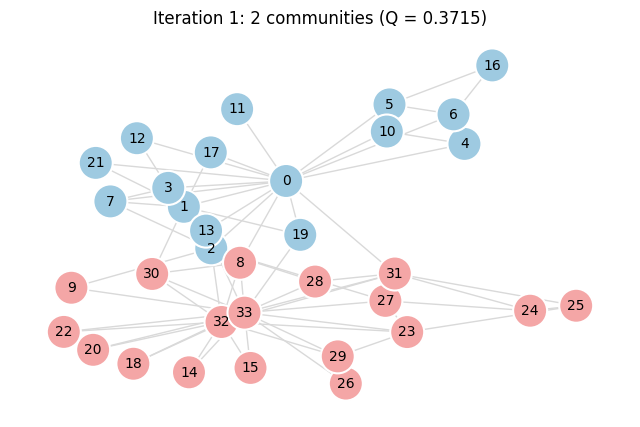


Level 1: Community = [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Leading eigenvalue = 1.1785
Delta Q = 0.0012


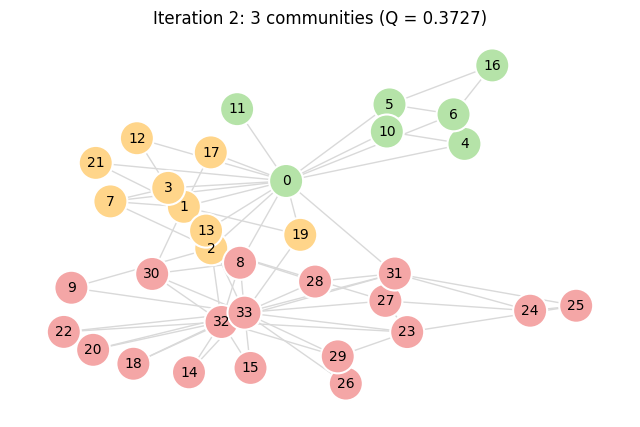


Level 2: Community = [0, 4, 5, 6, 10, 11, 16]
Leading eigenvalue = -0.0000

Level 2: Community = [1, 2, 3, 7, 12, 13, 17, 19, 21]
Leading eigenvalue = 0.0602
Delta Q = -0.0158

Level 1: Community = [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
Leading eigenvalue = 0.8594
Delta Q = 0.0207


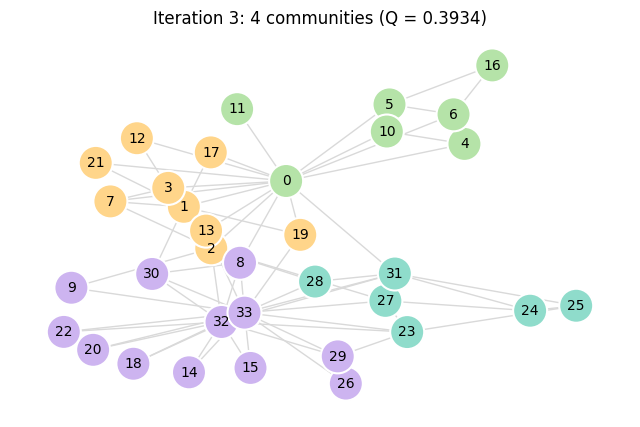


Level 2: Community = [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
Leading eigenvalue = 0.0000

Level 2: Community = [23, 24, 25, 27, 28, 31]
Leading eigenvalue = 0.0000

Final number of communities: 4
Community 1: [0, 4, 5, 6, 10, 11, 16]
Community 2: [1, 2, 3, 7, 12, 13, 17, 19, 21]
Community 3: [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]
Community 4: [23, 24, 25, 27, 28, 31]


In [84]:
all_nodes = list(G.nodes())
communities = []

recursive_split(G, B, all_nodes, communities)

print("\nFinal number of communities:", len(communities))

for i, community in enumerate(communities):
    print(f"Community {i + 1}: {community}")

#8. Plot the evolution of centrality measures

The following four plots show how each node's centrality values change from the original graph (iteration 0) through the recorded community splits. Each line represents one node, and the horizontal axis represents the iteration number.

The comparison should be interpreted with care: iteration 0 uses the whole graph, whereas subsequent iterations use the node's current community subgraph. Changes therefore reflect the changing network context as the communities become smaller.

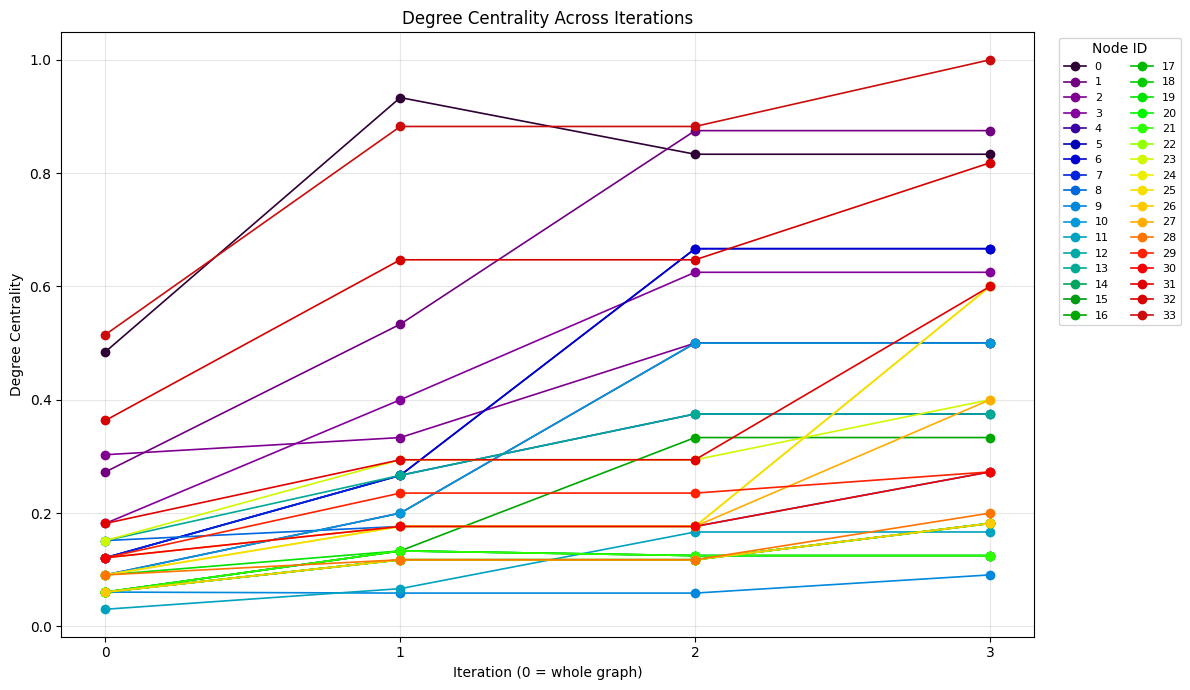

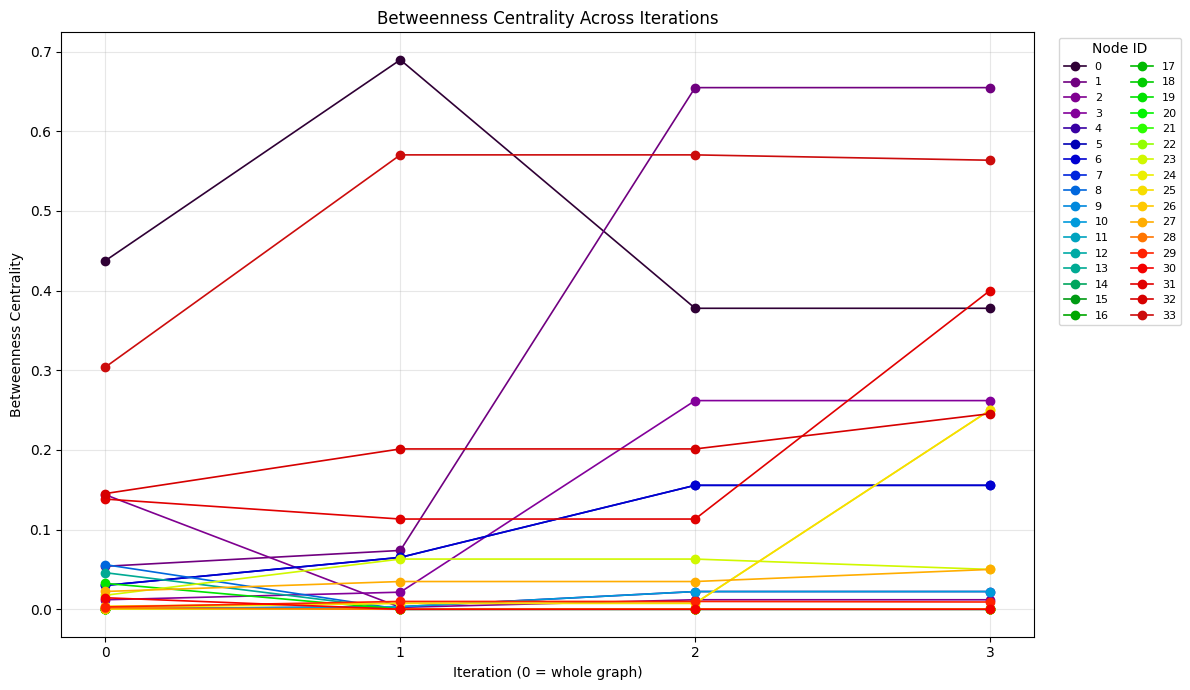

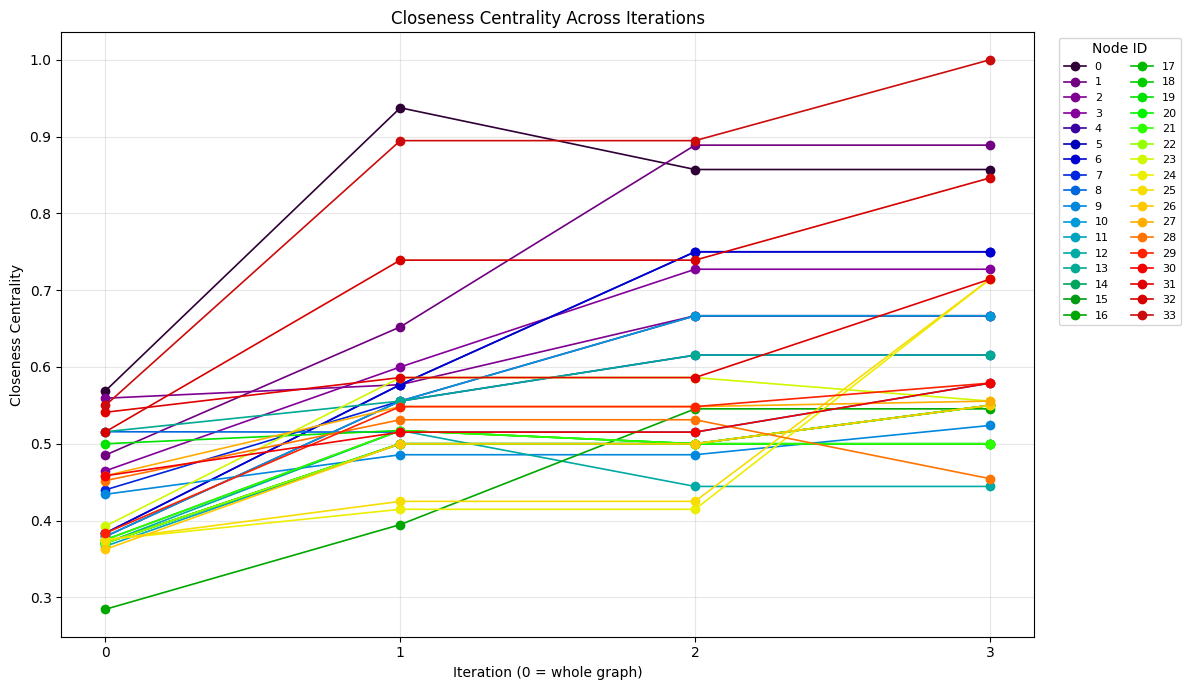

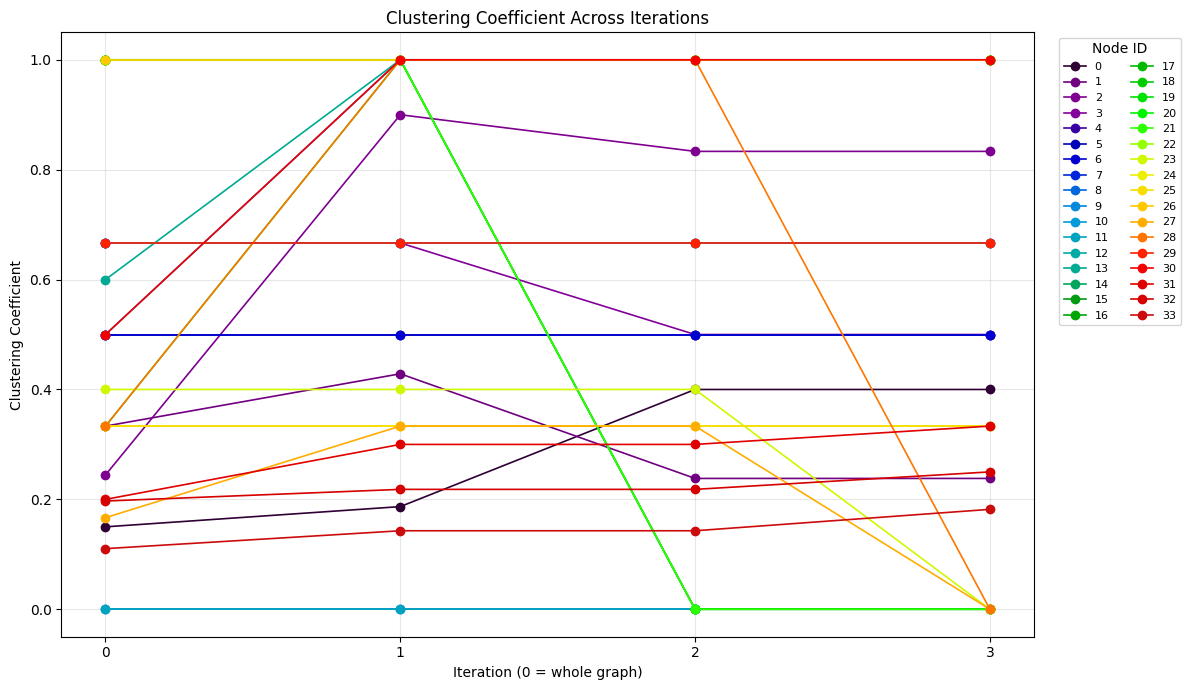

In [85]:
iterations = sorted(centrality_history) # 0 = whole graph, then one per split

metric_names = {
    "degree": "Degree Centrality",
    "betweenness": "Betweenness Centrality",
    "closeness": "Closeness Centrality",
    "clustering": "Clustering Coefficient"
}

node_colors_lines = plt.cm.nipy_spectral(np.linspace(0.02, 0.95, G.number_of_nodes()))

for metric, title in metric_names.items():
    plt.figure(figsize=(12, 7))

    for c, node in zip(node_colors_lines, sorted(G.nodes())):
        values = [centrality_history[i][metric][node] for i in iterations]
        plt.plot(iterations, values, marker="o", linewidth=1.2, color=c, label=str(node))

    plt.title(f"{title} Across Iterations")
    plt.xlabel("Iteration (0 = whole graph)")
    plt.ylabel(title)
    plt.xticks(iterations)
    plt.legend(title="Node ID", bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2, fontsize=8)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

#9.Identify nodes with five highest centrality measures at every iteration

Four measures are displayed for each node:
1. Degree centrality — the fraction of other nodes in the same graph or community to which a node is directly connected.
2. Betweenness centrality — the extent to which a node lies on shortest paths between pairs of nodes.
3. Closeness centrality — based on the shortest-path distances from a node to the other nodes.
4. Clustering coefficient — the proportion of possible connections among a node's neighbours that are present.

At each iterations, metrics are calculated on the induced subgraph of each community in the current partition. Consequently, the values describe each node's position within its current community, rather than within the original full graph.

In [86]:
from IPython.display import display, Markdown
from collections import Counter

def top5(iteration, metric):
    values = centrality_history[iteration][metric]
    return sorted(values.items(), key=lambda x: (-x[1], x[0]))[:5]

for iteration in sorted(centrality_history):
    table = [
        f"## Iteration {iteration}",
        "| Rank | Degree | Betweenness | Closeness | Clustering |",
        "|---:|---:|---:|---:|---:|"
    ]

    for i in range(5):
        row = [str(i + 1)]

        for metric in ["degree", "betweenness", "closeness", "clustering"]:
            node, value = top5(iteration, metric)[i]
            row.append(f"Node {node}: {value:.4f}")

        table.append("| " + " | ".join(row) + " |")

    display(Markdown("\n".join(table)))

## Iteration 0
| Rank | Degree | Betweenness | Closeness | Clustering |
|---:|---:|---:|---:|---:|
| 1 | Node 33: 0.5152 | Node 0: 0.4376 | Node 0: 0.5690 | Node 7: 1.0000 |
| 2 | Node 0: 0.4848 | Node 33: 0.3041 | Node 2: 0.5593 | Node 12: 1.0000 |
| 3 | Node 32: 0.3636 | Node 32: 0.1452 | Node 33: 0.5500 | Node 14: 1.0000 |
| 4 | Node 2: 0.3030 | Node 2: 0.1437 | Node 31: 0.5410 | Node 15: 1.0000 |
| 5 | Node 1: 0.2727 | Node 31: 0.1383 | Node 8: 0.5156 | Node 16: 1.0000 |

## Iteration 1
| Rank | Degree | Betweenness | Closeness | Clustering |
|---:|---:|---:|---:|---:|
| 1 | Node 0: 0.9333 | Node 0: 0.6897 | Node 0: 0.9375 | Node 7: 1.0000 |
| 2 | Node 33: 0.8824 | Node 33: 0.5703 | Node 33: 0.8947 | Node 8: 1.0000 |
| 3 | Node 32: 0.6471 | Node 32: 0.2012 | Node 32: 0.7391 | Node 12: 1.0000 |
| 4 | Node 1: 0.5333 | Node 31: 0.1132 | Node 1: 0.6522 | Node 13: 1.0000 |
| 5 | Node 3: 0.4000 | Node 1: 0.0738 | Node 3: 0.6000 | Node 14: 1.0000 |

## Iteration 2
| Rank | Degree | Betweenness | Closeness | Clustering |
|---:|---:|---:|---:|---:|
| 1 | Node 33: 0.8824 | Node 1: 0.6548 | Node 33: 0.8947 | Node 7: 1.0000 |
| 2 | Node 1: 0.8750 | Node 33: 0.5703 | Node 1: 0.8889 | Node 8: 1.0000 |
| 3 | Node 0: 0.8333 | Node 0: 0.3778 | Node 0: 0.8571 | Node 13: 1.0000 |
| 4 | Node 5: 0.6667 | Node 3: 0.2619 | Node 5: 0.7500 | Node 14: 1.0000 |
| 5 | Node 6: 0.6667 | Node 32: 0.2012 | Node 6: 0.7500 | Node 15: 1.0000 |

## Iteration 3
| Rank | Degree | Betweenness | Closeness | Clustering |
|---:|---:|---:|---:|---:|
| 1 | Node 33: 1.0000 | Node 1: 0.6548 | Node 33: 1.0000 | Node 7: 1.0000 |
| 2 | Node 1: 0.8750 | Node 33: 0.5636 | Node 1: 0.8889 | Node 8: 1.0000 |
| 3 | Node 0: 0.8333 | Node 31: 0.4000 | Node 0: 0.8571 | Node 13: 1.0000 |
| 4 | Node 32: 0.8182 | Node 0: 0.3778 | Node 32: 0.8462 | Node 14: 1.0000 |
| 5 | Node 5: 0.6667 | Node 3: 0.2619 | Node 5: 0.7500 | Node 15: 1.0000 |

#10. Result

The recursive spectral partitioning procedure performed three successful splits and produced four final communities:
- Community 1: nodes 0, 4, 5, 6, 10, 11, 16
- Community 2: nodes 1, 2, 3, 7, 12, 13, 17, 19, 21
- Community 3: nodes 8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33
- Community 4: nodes 23, 24, 25, 27, 28, 31

Modularity increased with every split: $Q=0.3715$ after the first split (two communities), $0.3727$ after the second (three communities) and $0.3934$ after the third (four communities).

#11. Discussion


---
Nodes That Remain Central

In the original Karate Club graph, nodes 0 and 33 have the highest degree and betweenness centrality. This indicates that they have many direct connections and play important roles in connecting different parts of the network. Node 0 also has the highest closeness centrality, suggesting that it can reach other nodes through relatively short paths.

Across the subsequent splits, nodes 0, 1 and 33 repeatedly appear among the top-ranked nodes in one or more of the centrality measures. This suggests that they continue to occupy important positions even after the network is divided into smaller communities.

A node may rank highly in one measure but not in another. For example, a node with high betweenness may act as a connector between different parts of a community, whereas a node with a high clustering coefficient belongs to a group whose neighbours are strongly interconnected.

---
Effect of Community Structure on Centrality

After each split, the centrality measures are calculated within the induced subgraphs of the resulting communities. Only connections between nodes belonging to the same community are considered. Connections to nodes outside that community are excluded.

This has several effects:

- Degree centrality: A node may lose connections when its neighbours are assigned to other communities. Its degree centrality can therefore decrease.
- Betweenness centrality: The shortest paths within a community may change after splitting. A node that previously acted as a bridge may become less important.
- Closeness centrality: Since the network is divided into smaller groups, the distances between nodes are recalculated within each community. This can change the relative closeness of nodes.
- Clustering coefficient: This measure depends on how many connections exist between a node's neighbours. If some of these neighbours are separated into different communities, the clustering coefficient may change.

Therefore, changes in centrality do not mean that the original network connections have physically changed. They reflect the different network structures being considered at each iteration.

---
Observations from the Final Communities

The communities produced are not all of equal size, indicating that the network does not divide into perfectly balanced groups. Instead, the splitting process identifies groups based on the network's connection structure.

---
Observations from the Clustering Coefficient

Some nodes achieve a clustering coefficient of 1.0 at different iterations. This means that all the neighbours of those nodes are connected to one another, forming a fully interconnected neighbourhood. However, a high clustering coefficient does not necessarily indicate high overall centrality.

A node may have only a few neighbours, but those neighbours may all be connected.This highlights the difference between being well-connected and belonging to a tightly connected local group.

---
Limitations

Sign-thresholding the leading eigenvector is a heuristic: spectral bisection alone does not guarantee the globally optimal partition. The metrics ignore edges between communities, which is exactly the information that gives bridge nodes their importance in the original network.

---

#12. Conclusion

This assignment applied recursive spectral modularity partitioning to Zachary's Karate Club graph. Using the leading eigenvector of the restricted modularity matrix, the algorithm performed three successful splits and obtained four final communities.

The graph visualizations show how the network is divided at each successful split. The centrality calculations and their iteration-wise plots show that nodes 0, 1 and 33 remain prominent in several measures.

This approach has several practical applications in real-world networks. In social networks, it can identify groups of people with strong interactions and influential individuals within those groups.
Similarly, in biological networks, community detection can reveal groups of interacting proteins or other biological components. Centrality measures can further help identify influential nodes, important connectors and highly interconnected groups in these systems.

The analysis demonstrates how modularity-based spectral partitioning can reveal community structure and how centrality measures can be used to examine the changing structural roles of nodes.

#13. References

1. Newman, M. E. J. (2006). Modularity and community structure in networks. Proceedings of the National Academy of Sciences, 103(23), 8577–8582. https://doi.org/10.1073/pnas.0601602103

2. Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. Journal of Anthropological Research, 33(4), 452–473.